In [36]:

%cd /content

!git clone https://github.com/karpathy/nanoGPT.git

%cd /content/nanoGPT



/content
fatal: destination path 'nanoGPT' already exists and is not an empty directory.
/content/nanoGPT


In [37]:
!ls


assets		 data	      README.md		  train.py
bench.py	 LICENSE      results		  transformer_sizing.ipynb
config		 model.py     sample.py
configurator.py  __pycache__  scaling_laws.ipynb


In [38]:
!pip install -q tiktoken transformers datasets

In [39]:
# !python data/shakespeare_char/prepare.py data/shakespeare_char/input.txt

!python data/shakespeare_char/prepare.py



length of dataset in characters: 1,115,394
all the unique characters: 
 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
vocab size: 65
train has 1,003,854 tokens
val has 111,540 tokens


In [40]:
!ls -lh data/shakespeare_char/

total 6.3M
-rw-r--r-- 1 root root 3.1M Nov  8 04:11 ckpt-1.pt
-rw-r--r-- 1 root root 1.1M Nov  8 01:52 input.txt
-rw-r--r-- 1 root root  703 Nov  8 04:35 meta.pkl
-rw-r--r-- 1 root root 2.3K Nov  8 01:51 prepare.py
-rw-r--r-- 1 root root  209 Nov  8 01:51 readme.md
-rw-r--r-- 1 root root 2.0M Nov  8 04:35 train.bin
-rw-r--r-- 1 root root 218K Nov  8 04:35 val.bin


In [41]:
%cd /content/nanoGPT

import os
import itertools
import subprocess
import time
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

os.makedirs("results/member3", exist_ok=True)

print("Group 7 - Member 3 setup complete!")

/content/nanoGPT
Group 7 - Member 3 setup complete!


In [42]:
experiments = list(itertools.product(
    [4, 8],          # n_head
    [128, 256],      # n_embd
    [8, 16],         # batch_size
    [1000, 2000],   # max_iters
    [0.1, 0.2]       # dropout
))

configs = []

for i, (heads, embd, batch, steps, dropout) in enumerate(experiments, 1):
    configs.append({
        "run": f"g3_{i:02d}",
        "n_head": heads,
        "n_embd": embd,
        "batch_size": batch,
        "max_iters": steps,
        "dropout": dropout
    })

df = pd.DataFrame(configs)

display(df)

print("Total experiments:", len(df))

,run,n_head,n_embd,batch_size,max_iters,dropout
0,g3_01,4,128,8,1000,0.1
1,g3_02,4,128,8,1000,0.2
2,g3_03,4,128,8,2000,0.1
3,g3_04,4,128,8,2000,0.2
4,g3_05,4,128,16,1000,0.1
5,g3_06,4,128,16,1000,0.2
6,g3_07,4,128,16,2000,0.1
7,g3_08,4,128,16,2000,0.2
8,g3_09,4,256,8,1000,0.1
9,g3_10,4,256,8,1000,0.2


Total experiments: 32


In [43]:
# Make checkpoint loading compatible with newer PyTorch
sample_path = Path("sample.py")
code = sample_path.read_text()

code = code.replace(
    "torch.load(ckpt_path, map_location=device)",
    "torch.load(ckpt_path, map_location=device, weights_only=False)"
)

sample_path.write_text(code)

# Add GPU memory reporting to train.py
train_path = Path("train.py")
code = train_path.read_text()

if "PEAK_GPU_MEMORY_MB:" not in code:
    code += """
if device_type == 'cuda':
    print('PEAK_GPU_MEMORY_MB:', torch.cuda.max_memory_allocated() / 1024**2)
"""
    train_path.write_text(code)

print("Training and sampling scripts ready!")

Training and sampling scripts ready!


In [58]:
import re

START = 24
END = 32

results_file = Path("results/member3/results.csv")

# Keep previous results when running the next batch
if results_file.exists():
    results = pd.read_csv(results_file).to_dict("records")
else:
    results = []

def get_losses(log):
    matches = re.findall(
        r"step (\d+): train loss ([\d.]+), val loss ([\d.]+)",
        log
    )
    return matches

def get_memory(log):
    match = re.search(r"PEAK_GPU_MEMORY_MB:\s*([\d.]+)", log)
    return float(match.group(1)) if match else None

for config in configs[START:END]:

    run = config["run"]

    # Don't repeat completed experiments
    if run in [r["run"] for r in results]:
        print("Skipping completed:", run)
        continue

    print(f"\n========== Training {run} ==========")

    out_dir = f"results/member3/{run}"
    os.makedirs(out_dir, exist_ok=True)

    command = [
        "python", "train.py",
        "config/train_shakespeare_char.py",
        "--device=cuda",
        "--compile=False",
        "--dtype=float32",
        "--init_from=scratch",
        "--wandb_log=False",
        "--block_size=128",
        "--n_layer=4",
        f"--n_head={config['n_head']}",
        f"--n_embd={config['n_embd']}",
        f"--batch_size={config['batch_size']}",
        f"--max_iters={config['max_iters']}",
        f"--dropout={config['dropout']}",
        "--gradient_accumulation_steps=1",
        "--learning_rate=0.001",
        "--warmup_iters=100",
        "--lr_decay_iters=2000",
        "--min_lr=0.0001",
        "--beta2=0.99",
        "--eval_interval=250",
        "--eval_iters=20",
        "--log_interval=50",
        "--always_save_checkpoint=True",
        f"--out_dir={out_dir}"
    ]

    start_time = time.time()

    process = subprocess.run(
        command,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    elapsed = time.time() - start_time
    log = process.stdout

    # Save full training log inside Colab
    Path(f"{out_dir}/training.log").write_text(log)

    if process.returncode != 0:
        print("Training failed:", run)
        print(log[-3000:])
        break

    losses = get_losses(log)

    if not losses:
        print("Could not read training losses.")
        print(log[-2000:])
        break

    final_step, train_loss, val_loss = losses[-1]

    # Save loss history for graphs
    history = pd.DataFrame(
        losses, columns=["step", "train_loss", "val_loss"]
    )
    history = history.astype(float)
    history.to_csv(f"{out_dir}/loss_history.csv", index=False)

    # Generate text with this trained model
    sample_command = [
        "python", "sample.py",
        "--device=cuda",
        "--compile=False",
        f"--out_dir={out_dir}",
        "--start=ROMEO:",
        "--num_samples=1",
        "--max_new_tokens=200",
        "--temperature=0.8",
        "--top_k=40"
    ]

    sample = subprocess.run(
        sample_command,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    Path(f"{out_dir}/sample.txt").write_text(sample.stdout)

    if sample.returncode != 0:
        print("Sampling warning:", sample.stdout[-1000:])

    # Count unique model parameters from checkpoint
    import torch

    checkpoint = torch.load(
        f"{out_dir}/ckpt.pt",
        map_location="cpu",
        weights_only=False
    )

    state = checkpoint["model"]
    parameters = sum(
        tensor.numel() for name, tensor in state.items()
        if not name.endswith(".attn.bias")
    )

    del checkpoint, state

    row = {
        **config,
        "train_loss": float(train_loss),
        "val_loss": float(val_loss),
        "time_seconds": round(elapsed, 2),
        "parameters": parameters,
        "peak_gpu_mb": get_memory(log)
    }

    results.append(row)

    # Save results after every experiment
    pd.DataFrame(results).to_csv(results_file, index=False)

    print(
        f"{run} completed | "
        f"Train: {train_loss} | "
        f"Validation: {val_loss} | "
        f"Time: {elapsed:.1f}s"
    )

print("\nCompleted experiments:", len(results))


========== Training g3_25 ==========
g3_25 completed | Train: 1.9251 | Validation: 2.0236 | Time: 14.9s

========== Training g3_26 ==========
g3_26 completed | Train: 2.0358 | Validation: 2.1105 | Time: 15.2s

========== Training g3_27 ==========
g3_27 completed | Train: 1.6372 | Validation: 1.8278 | Time: 27.5s

========== Training g3_28 ==========
g3_28 completed | Train: 1.7430 | Validation: 1.9059 | Time: 26.2s

========== Training g3_29 ==========
g3_29 completed | Train: 1.6753 | Validation: 1.8415 | Time: 24.9s

========== Training g3_30 ==========
g3_30 completed | Train: 1.7784 | Validation: 1.9177 | Time: 24.8s

========== Training g3_31 ==========
g3_31 completed | Train: 1.4599 | Validation: 1.6299 | Time: 44.5s

========== Training g3_32 ==========
g3_32 completed | Train: 1.5513 | Validation: 1.7094 | Time: 44.8s

Completed experiments: 32


In [59]:
import pandas as pd

df = pd.read_csv("results/member3/results.csv")

print("Completed experiments:", len(df))
print("Unique experiments:", df["run"].nunique())

display(df)

Completed experiments: 32
Unique experiments: 32


,run,n_head,n_embd,batch_size,max_iters,dropout,train_loss,val_loss,time_seconds,parameters,peak_gpu_mb
0,g3_01,4,128,8,1000,0.1,2.2211,2.2387,13.73,820608,63.995605
1,g3_02,4,128,8,1000,0.2,2.2973,2.3020,13.44,820608,63.995605
2,g3_03,4,128,8,2000,0.1,2.0195,2.0815,22.89,820608,63.995605
3,g3_04,4,128,8,2000,0.2,2.1478,2.1757,24.50,820608,63.995605
4,g3_05,4,128,16,1000,0.1,2.0351,2.1191,13.58,820608,100.397949
5,g3_06,4,128,16,1000,0.2,2.1552,2.2162,13.45,820608,100.397949
6,g3_07,4,128,16,2000,0.1,1.8146,1.9511,22.87,820608,100.397949
7,g3_08,4,128,16,2000,0.2,1.9677,2.0523,22.94,820608,100.397949
8,g3_09,4,256,8,1000,0.1,1.8868,2.0071,14.04,3214080,128.073730
9,g3_10,4,256,8,1000,0.2,2.0173,2.0934,14.51,3214080,128.073730


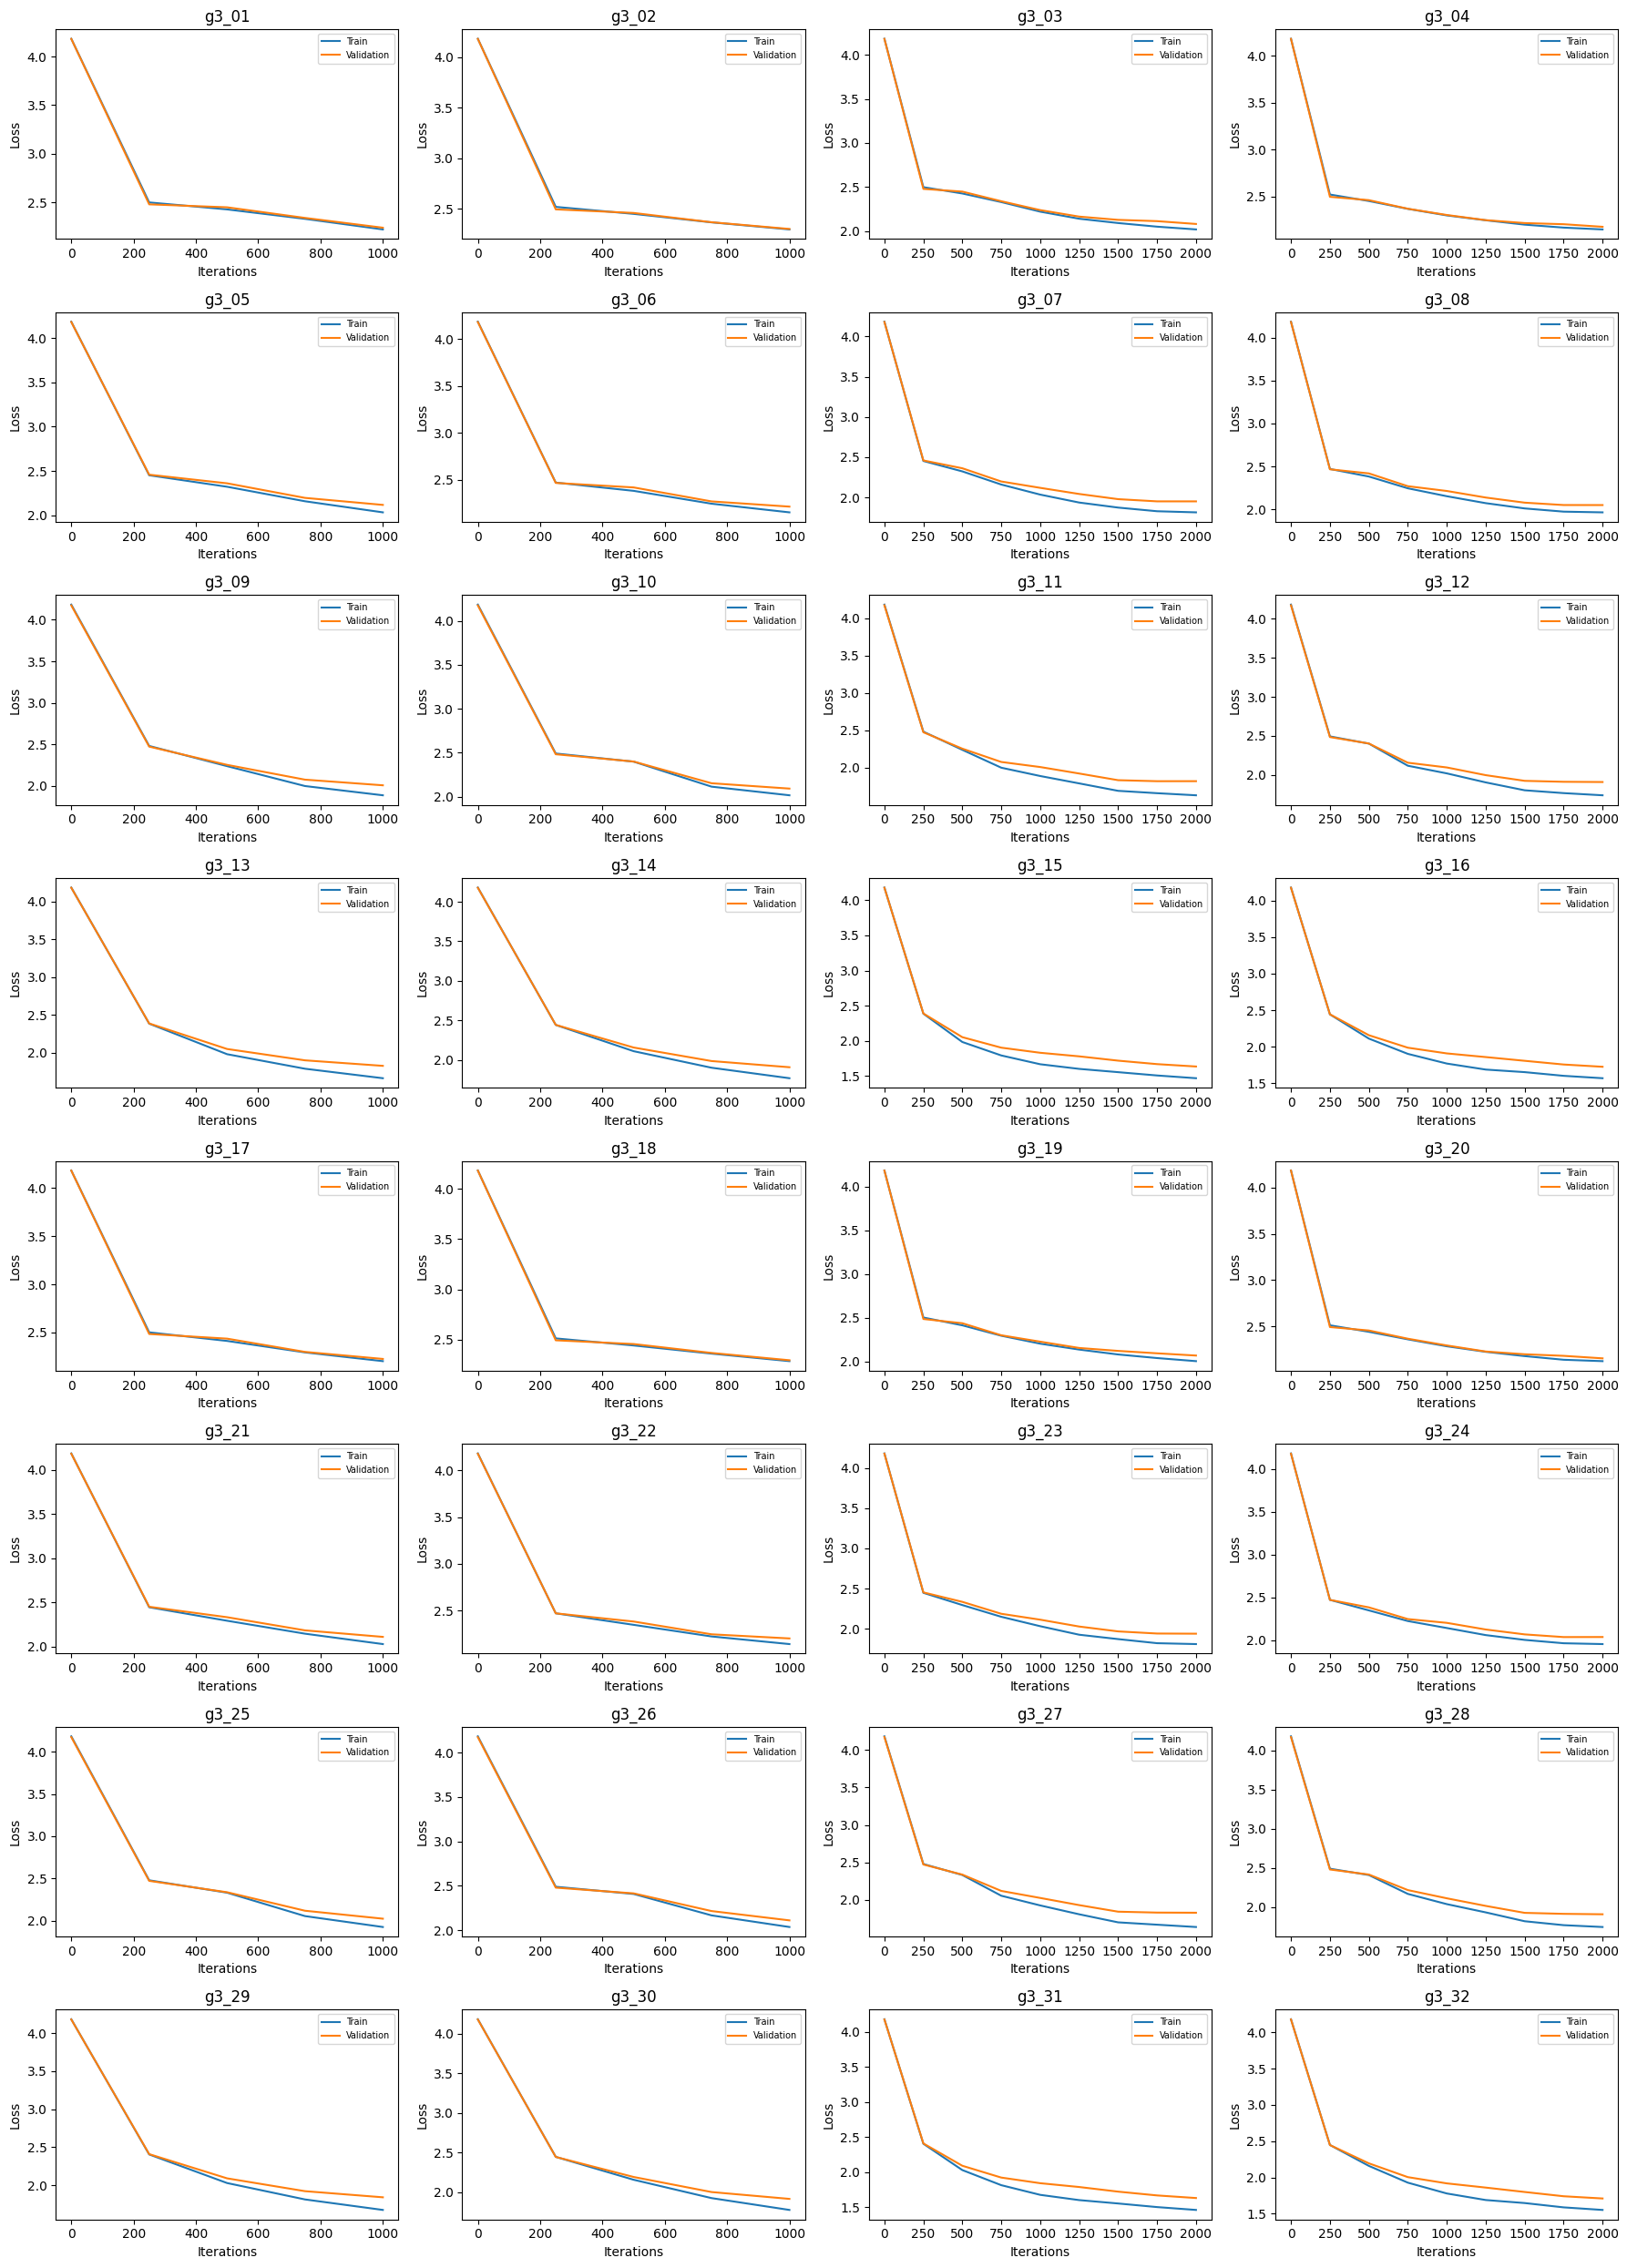

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

df = pd.read_csv("results/member3/results.csv")

fig, axes = plt.subplots(8, 4, figsize=(18, 25))

for ax, run in zip(axes.flat, df["run"]):
    history = pd.read_csv(
        f"results/member3/{run}/loss_history.csv"
    )

    ax.plot(history["step"], history["train_loss"], label="Train")
    ax.plot(history["step"], history["val_loss"], label="Validation")
    ax.set_title(run)
    ax.set_xlabel("Iterations")
    ax.set_ylabel("Loss")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig("results/member3/loss_curves.png", dpi=150)
plt.show()


 n_head
n_head
4    2.0034
8    1.9998
Name: val_loss, dtype: float64

 n_embd
n_embd
128    2.1354
256    1.8677
Name: val_loss, dtype: float64

 batch_size
batch_size
8     2.0771
16    1.9261
Name: val_loss, dtype: float64

 max_iters
max_iters
1000    2.0900
2000    1.9132
Name: val_loss, dtype: float64

 dropout
dropout
0.1    1.9588
0.2    2.0443
Name: val_loss, dtype: float64


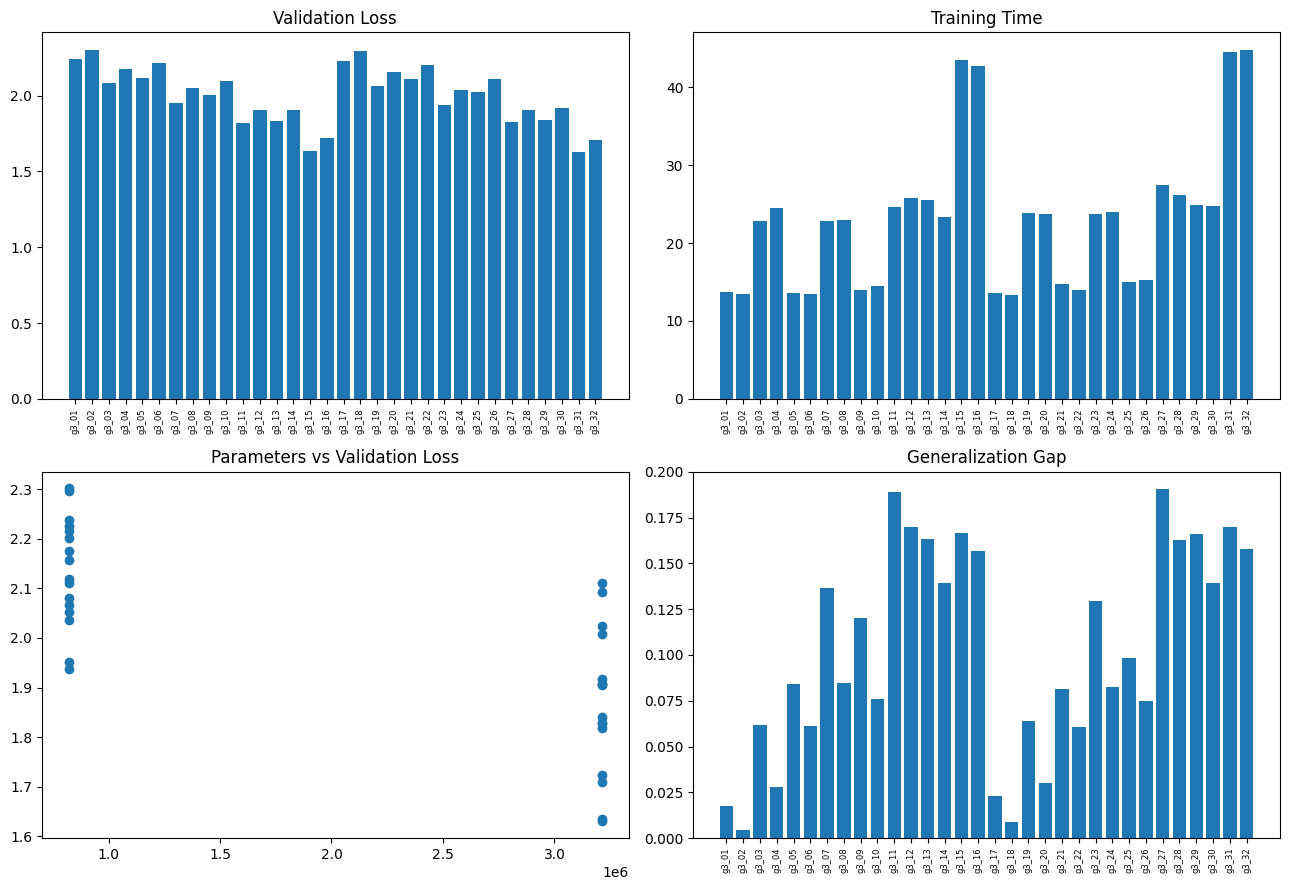

In [61]:
df["loss_gap"] = df["val_loss"] - df["train_loss"]

for parameter in [
    "n_head", "n_embd", "batch_size",
    "max_iters", "dropout"
]:
    print("\n", parameter)
    print(df.groupby(parameter)["val_loss"].mean().round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].bar(df["run"], df["val_loss"])
axes[0, 0].set_title("Validation Loss")

axes[0, 1].bar(df["run"], df["time_seconds"])
axes[0, 1].set_title("Training Time")

axes[1, 0].scatter(df["parameters"], df["val_loss"])
axes[1, 0].set_title("Parameters vs Validation Loss")

axes[1, 1].bar(df["run"], df["loss_gap"])
axes[1, 1].set_title("Generalization Gap")

for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.tick_params(axis="x", rotation=90, labelsize=6)

plt.tight_layout()
plt.savefig("results/member3/comparisons.png", dpi=150)
plt.show()

In [63]:
import subprocess
from pathlib import Path

for i in range(1, 33):
    run = f"g3_{i:02d}"
    folder = Path(f"results/member3/{run}")

    result = subprocess.run(
        [
            "python", "sample.py",
            "--device=cpu",
            "--compile=False",
            f"--out_dir={folder}",
            "--start=ROMEO:",
            "--num_samples=1",
            "--max_new_tokens=200",
            "--temperature=0.8",
            "--top_k=40",
            "--seed=1337"
        ],
        capture_output=True,
        text=True
    )

    if result.returncode == 0:
        (folder / "sample.txt").write_text(result.stdout)
        print(run, "completed")
    else:
        print(run, "FAILED:", result.stderr[-500:])

g3_01 completed
g3_02 completed
g3_03 completed
g3_04 completed
g3_05 completed
g3_06 completed
g3_07 completed
g3_08 completed
g3_09 completed
g3_10 completed
g3_11 completed
g3_12 completed
g3_13 completed
g3_14 completed
g3_15 completed
g3_16 completed
g3_17 completed
g3_18 completed
g3_19 completed
g3_20 completed
g3_21 completed
g3_22 completed
g3_23 completed
g3_24 completed
g3_25 completed
g3_26 completed
g3_27 completed
g3_28 completed
g3_29 completed
g3_30 completed
g3_31 completed
g3_32 completed


In [64]:
import pandas as pd
from pathlib import Path

df = pd.read_csv("results/member3/results.csv")

best = df.loc[df["val_loss"].idxmin()]
worst = df.loc[df["val_loss"].idxmax()]

print("BEST MODEL:")
display(best.to_frame().T)
print(Path(f"results/member3/{best['run']}/sample.txt").read_text())

print("\nWORST MODEL:")
display(worst.to_frame().T)
print(Path(f"results/member3/{worst['run']}/sample.txt").read_text())

BEST MODEL:


,run,n_head,n_embd,batch_size,max_iters,dropout,train_loss,val_loss,time_seconds,parameters,peak_gpu_mb
30,g3_31,8,256,16,2000,0.1,1.4599,1.6299,44.51,3214080,198.851074


Overriding: device = cpu
Overriding: compile = False
Overriding: out_dir = results/member3/g3_31
Overriding: start = ROMEO:
Overriding: num_samples = 1
Overriding: max_new_tokens = 200
Overriding: temperature = 0.8
Overriding: top_k = 40
Overriding: seed = 1337
number of parameters: 3.16M
Loading meta from data/shakespeare_char/meta.pkl...
ROMEO:
Whell is a mease, appear of our speak the mind.

DUKE VINCENTIO:
We doth need.

POLIXENES:
A bosure of you music: not the good,
I would posse.

DUCHESS OF YORK:
What is tuch wrather with my bods,
Who
---------------


WORST MODEL:


,run,n_head,n_embd,batch_size,max_iters,dropout,train_loss,val_loss,time_seconds,parameters,peak_gpu_mb
1,g3_02,4,128,8,1000,0.2,2.2973,2.302,13.44,820608,63.995605


Overriding: device = cpu
Overriding: compile = False
Overriding: out_dir = results/member3/g3_02
Overriding: start = ROMEO:
Overriding: num_samples = 1
Overriding: max_new_tokens = 200
Overriding: temperature = 0.8
Overriding: top_k = 40
Overriding: seed = 1337
number of parameters: 0.80M
Loading meta from data/shakespeare_char/meta.pkl...
ROMEO:
I it you--uren yor ou geare ourd hases
An.

DUF ESTKENGRD E II:
Tho, aky I sorereach thower meamous, dand yout henid!

WASIST:
A at be m wit ble an nding t foupenet an t ward oum ar mides
And relimy 
---------------



In [65]:
from pathlib import Path

base = Path("results/member3")

print("Results CSV:", (base / "results.csv").exists())
print("Loss curves:", (base / "loss_curves.png").exists())
print("Comparison graphs:", (base / "comparisons.png").exists())

samples = list(base.glob("g3_*/sample.txt"))
histories = list(base.glob("g3_*/loss_history.csv"))

print("Generated samples:", len(samples), "/ 32")
print("Loss histories:", len(histories), "/ 32")

Results CSV: True
Loss curves: True
Comparison graphs: True
Generated samples: 32 / 32
Loss histories: 32 / 32


In [46]:
!ls -lh /content/nanoGPT/data/shakespeare_char/meta.pkl

-rw-r--r-- 1 root root 703 Nov  8 04:35 /content/nanoGPT/data/shakespeare_char/meta.pkl


In [47]:
!cp data/shakespeare_char/meta.pkl results/member3/g3_01/meta.pkl

In [48]:
%cd /content/nanoGPT

import os
import pickle

# Find the metadata file
meta_path = "data/shakespeare_char/meta.pkl"

print("Metadata exists:", os.path.exists(meta_path))

# Check the saved checkpoint
import torch

ckpt = torch.load(
    "results/member3/g3_01/ckpt.pt",
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:", list(ckpt.keys()))

/content/nanoGPT
Metadata exists: True
Checkpoint keys: ['model', 'model_args']


In [49]:
from pathlib import Path

path = Path("sample.py")
code = path.read_text()

# Use the Shakespeare character dataset
code = code.replace(
    "dataset = config.get('dataset', 'shakespeare_char')",
    "dataset = 'shakespeare_char'"
)

# Make the metadata path explicit
code = code.replace(
    "meta_path = os.path.join('data', dataset, 'meta.pkl')",
    "meta_path = 'data/shakespeare_char/meta.pkl'"
)

path.write_text(code)

print("Sampling metadata path updated.")

Sampling metadata path updated.


In [54]:
%cd /content/nanoGPT

from pathlib import Path

path = Path("sample.py")
code = path.read_text()

start = code.index("# look for the meta pickle")
end = code.index("if load_meta:", start)

fix = """# Use Shakespeare character vocabulary
meta_path = 'data/shakespeare_char/meta.pkl'
load_meta = True

"""

code = code[:start] + fix + code[end:]
path.write_text(code)

print("Fix applied!")
print("Metadata exists:", Path(meta_path).exists() if 'meta_path' in globals() else Path("data/shakespeare_char/meta.pkl").exists())

/content/nanoGPT
Fix applied!
Metadata exists: True


# New Section

In [52]:
# !sed -i "s/torch.load(ckpt_path, map_location=device)/torch.load(ckpt_path, map_location=device, weights_only=False)/" /content/nanoGPT/sample.py

In [53]:
# !python sample.py --device=cuda --out_dir=out --start="ROMEO: " --max_new_tokens=200

